# Modelo de risco de crédito: probabilidade de inadimplência em cartão de crédito

# Contents <a id='back'></a>

* [Introdução](#intro)
* [Etapa 1. Carregando e preparando os dados](#data_review)
* [Etapa 2. Análise exploratória (EDA)](#eda)
* [Etapa 3. Engenharia de variáveis](#features)
* [Etapa 4. Divisão dos dados](#split)
* [Etapa 5. Poder preditivo das variáveis: WoE e IV](#woe)
* [Etapa 6. Modelo 1: Scorecard com Regressão Logística](#scorecard)
* [Etapa 7. Modelo 2: LightGBM](#lgbm)
* [Etapa 8. Comparação dos modelos](#comparison)
* [Etapa 9. Explicabilidade com SHAP](#shap)
* [Etapa 10. Faixas de risco e política de crédito](#policy)
* [Etapa 11. Estabilidade e equidade do modelo](#monitoring)
* [Conclusão geral](#end)

## Introdução <a id='intro'></a>

Toda vez que um banco concede ou mantém crédito, ele assume o risco de não receber. Para gerenciar esse risco, os bancos estimam a **PD (probabilidade de inadimplência)** de cada cliente e usam essa estimativa para decidir **quem aprovar, qual limite oferecer e onde concentrar a cobrança**.

Neste projeto, vou construir um modelo de risco de crédito que estima a probabilidade de um cliente de cartão de crédito ficar inadimplente no mês seguinte.

### Objetivo:
- Entender quais características e comportamentos estão ligados à inadimplência
- Medir o poder preditivo de cada variável com **WoE e IV**, ferramentas padrão do mercado de crédito
- Construir e comparar dois modelos: um **scorecard** com Regressão Logística, interpretável como os usados em bancos, e um **LightGBM**
- Avaliar os modelos com as métricas usadas em crédito: **AUC, Gini, KS e calibração**
- Explicar as previsões com **SHAP**
- Transformar o modelo em uma **política de crédito**, com faixas de risco e o impacto de cada ponto de corte
- Verificar a **estabilidade** e a **equidade** do modelo

### Descrição dos dados

**Default of Credit Card Clients**, dados reais de 30.000 clientes de cartão de crédito de um banco de Taiwan, de abril a setembro de 2005. Os valores estão em novos dólares taiwaneses (NT\$).

- Fonte: Yeh, I. C., & Lien, C. H. (2009). *The comparisons of data mining techniques for the predictive accuracy of probability of default of credit card clients*. Expert Systems with Applications, 36(2). Disponível no UCI Machine Learning Repository, licença CC BY 4.0.

| Coluna original | Descrição |
|---|---|
| `LIMIT_BAL` | Limite de crédito do cliente |
| `SEX`, `EDUCATION`, `MARRIAGE`, `AGE` | Sexo, escolaridade, estado civil e idade |
| `PAY_0`, `PAY_2` a `PAY_6` | Situação de pagamento de setembro (mais recente) a abril |
| `BILL_AMT1` a `BILL_AMT6` | Valor da fatura de setembro a abril |
| `PAY_AMT1` a `PAY_AMT6` | Valor pago de setembro a abril |
| `default payment next month` | **Alvo:** 1 se o cliente ficou inadimplente no mês seguinte |

[Voltar ao Índice](#back)

## Etapa 1. Carregando e preparando os dados <a id='data_review'></a>

Se estiver usando o Google Colab ou outro Jupyter online, as bibliotecas abaixo já costumam estar instaladas. Se alguma faltar, basta tirar o `#` da linha de instalação.

In [1]:
# Instalação das bibliotecas (só é necessário se alguma não estiver instalada)
# %pip install pandas numpy matplotlib seaborn scikit-learn lightgbm shap

In [2]:
# Importa as bibliotecas necessárias
import os  # Utilizada para verificar se o arquivo de dados existe na pasta
import warnings  # Utilizada para esconder avisos que não afetam o resultado

import numpy as np  # Utilizada para operações numéricas
import pandas as pd  # Utilizada para manipulação de dados em DataFrames
import matplotlib.pyplot as plt  # Utilizada para a construção de gráficos
import seaborn as sns  # Utilizada para gráficos estatísticos
import lightgbm as lgb  # Modelo de gradient boosting baseado em árvores
import shap  # Utilizada para explicar as previsões do modelo
from sklearn.model_selection import train_test_split  # Utilizada para dividir os dados
from sklearn.linear_model import LogisticRegression  # Modelo do scorecard
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss  # Métricas de avaliação
from sklearn.calibration import calibration_curve  # Utilizada para avaliar a calibração

warnings.filterwarnings("ignore")  # Esconde avisos que não afetam o resultado

# Padroniza a aparência dos gráficos
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
AZUL, LARANJA, CINZA, VERMELHO = "#1f4e79", "#e07b00", "#9aa5b1", "#c0392b"
SEMENTE = 42  # Semente para garantir que os resultados sejam reproduzíveis

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Caminho do arquivo local e cópia no GitHub (usada se o arquivo não estiver na pasta)
ARQUIVO = "default_of_credit_card_clients.csv"
URL_GITHUB = "https://raw.githubusercontent.com/gabrieldeoliver1/Projetos/main/Projeto_18/default_of_credit_card_clients.csv"

if not os.path.exists(ARQUIVO):
    ARQUIVO = URL_GITHUB  # O pandas lê o arquivo direto da internet
    print("Lendo o arquivo do GitHub.")

dados = pd.read_csv(ARQUIVO)
print(f"Linhas: {dados.shape[0]} | Colunas: {dados.shape[1]}")
dados.head()

Linhas: 30000 | Colunas: 25


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


### Renomeando as colunas

Vou traduzir os nomes para facilitar a leitura. Nos meses, o número 1 é o mais recente (setembro) e o 6 é o mais antigo (abril). A coluna `PAY_0` é renomeada para `atraso_1`, para seguir a mesma numeração das outras.

In [4]:
# Dicionário com os novos nomes das colunas
novos_nomes = {"LIMIT_BAL": "limite", "SEX": "sexo", "EDUCATION": "escolaridade", "MARRIAGE": "estado_civil",
               "AGE": "idade", "PAY_0": "atraso_1", "default payment next month": "inadimplente"}
for i in range(2, 7):
    novos_nomes[f"PAY_{i}"] = f"atraso_{i}"  # Situação de pagamento do mês i
for i in range(1, 7):
    novos_nomes[f"BILL_AMT{i}"] = f"fatura_{i}"  # Valor da fatura do mês i
    novos_nomes[f"PAY_AMT{i}"] = f"pagamento_{i}"  # Valor pago no mês i

dados = dados.rename(columns=novos_nomes).drop(columns="ID")  # O ID não tem valor preditivo

# Listas de colunas usadas ao longo do notebook
COLS_ATRASO = [f"atraso_{i}" for i in range(1, 7)]
COLS_FATURA = [f"fatura_{i}" for i in range(1, 7)]
COLS_PAGAMENTO = [f"pagamento_{i}" for i in range(1, 7)]
dados.columns.tolist()

['limite',
 'sexo',
 'escolaridade',
 'estado_civil',
 'idade',
 'atraso_1',
 'atraso_2',
 'atraso_3',
 'atraso_4',
 'atraso_5',
 'atraso_6',
 'fatura_1',
 'fatura_2',
 'fatura_3',
 'fatura_4',
 'fatura_5',
 'fatura_6',
 'pagamento_1',
 'pagamento_2',
 'pagamento_3',
 'pagamento_4',
 'pagamento_5',
 'pagamento_6',
 'inadimplente']

In [5]:
# Verifica valores ausentes, duplicados e os tipos de dados
print(f"Valores ausentes: {dados.isna().sum().sum()}")
print(f"Linhas duplicadas: {dados.duplicated().sum()}")
print(f"Tipos de dados: {dados.dtypes.value_counts().to_dict()}")

Valores ausentes: 0
Linhas duplicadas: 35
Tipos de dados: {dtype('int64'): 24}


Não há valores ausentes, e todas as colunas são numéricas. As poucas linhas duplicadas representam clientes diferentes com o mesmo perfil (o ID foi removido), então serão mantidas.

### Corrigindo categorias inconsistentes

Segundo a documentação da base, a escolaridade deveria ter os códigos 1 a 4 e o estado civil, 1 a 3. Os códigos 0, 5 e 6 de escolaridade e o 0 de estado civil não estão documentados, então serão agrupados em "outros".

In [6]:
# Mostra a contagem de cada código antes da correção
print("Escolaridade:", dados["escolaridade"].value_counts().sort_index().to_dict())
print("Estado civil:", dados["estado_civil"].value_counts().sort_index().to_dict())

# Agrupa os códigos não documentados na categoria 4 (outros)
dados["escolaridade"] = dados["escolaridade"].replace({0: 4, 5: 4, 6: 4})
dados["estado_civil"] = dados["estado_civil"].replace({0: 3})

# Rótulos legíveis, usados nos gráficos
ROTULO_ESCOLARIDADE = {1: "Pós-graduação", 2: "Universidade", 3: "Ensino médio", 4: "Outros"}
ROTULO_ESTADO_CIVIL = {1: "Casado", 2: "Solteiro", 3: "Outros"}
ROTULO_SEXO = {1: "Masculino", 2: "Feminino"}

Escolaridade: {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
Estado civil: {0: 54, 1: 13659, 2: 15964, 3: 323}


### Entendendo a situação de pagamento

As colunas `atraso_1` a `atraso_6` são as mais importantes da base. Os códigos significam:

| Código | Significado |
|---|---|
| -2 | Sem consumo no mês |
| -1 | Fatura paga integralmente |
| 0 | Pagamento parcial (uso do crédito rotativo), sem atraso |
| 1 a 9 | Meses de atraso no pagamento |

[Voltar ao Índice](#back)

## Etapa 2. Análise exploratória (EDA) <a id='eda'></a>

### Taxa de inadimplência

In [7]:
taxa_geral = dados["inadimplente"].mean()
print(f"Taxa de inadimplência: {taxa_geral:.1%}")
print(f"Clientes inadimplentes: {dados['inadimplente'].sum():,} de {len(dados):,}".replace(",", "."))

Taxa de inadimplência: 22.1%
Clientes inadimplentes: 6.636 de 30.000


Cerca de **22% dos clientes** ficaram inadimplentes. As classes são desbalanceadas, por isso a **acurácia não é uma boa métrica** aqui: um modelo que dissesse que ninguém fica inadimplente acertaria 78% dos casos e seria inútil. Vou usar AUC, Gini e KS, as métricas padrão em crédito.

### O histórico de pagamento

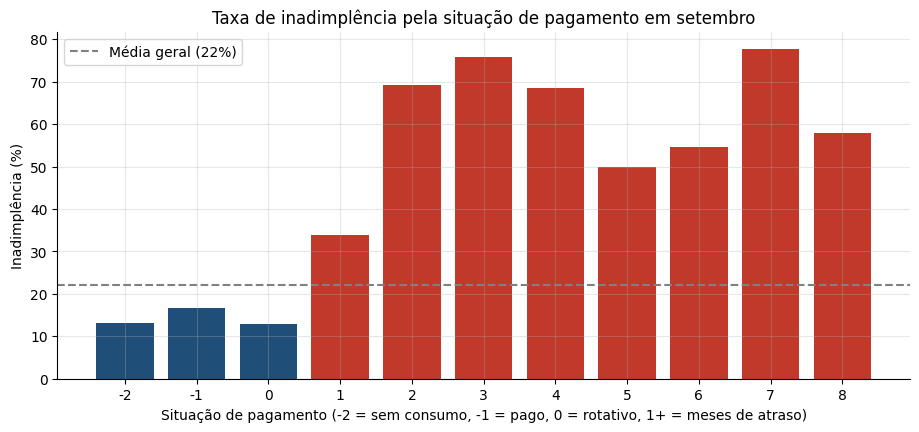

,taxa,clientes
atraso_1,,
-2,13.2,2759
-1,16.8,5686
0,12.8,14737
1,33.9,3688
2,69.1,2667
3,75.8,322
4,68.4,76
5,50.0,26
6,54.5,11


In [8]:
# Taxa de inadimplência por situação de pagamento no mês mais recente
taxa_por_atraso = dados.groupby("atraso_1")["inadimplente"].agg(["mean", "size"])
taxa_por_atraso.columns = ["taxa", "clientes"]

fig, ax = plt.subplots()
cores = [VERMELHO if s > 0 else AZUL for s in taxa_por_atraso.index]
ax.bar(taxa_por_atraso.index.astype(str), taxa_por_atraso["taxa"] * 100, color=cores)
ax.axhline(taxa_geral * 100, color="gray", ls="--", label=f"Média geral ({taxa_geral:.0%})")
ax.set_title("Taxa de inadimplência pela situação de pagamento em setembro")
ax.set_xlabel("Situação de pagamento (-2 = sem consumo, -1 = pago, 0 = rotativo, 1+ = meses de atraso)")
ax.set_ylabel("Inadimplência (%)")
ax.legend()
plt.show()
taxa_por_atraso.assign(taxa=lambda d: (d.taxa * 100).round(1))

O histórico de pagamento é, de longe, o sinal mais forte. Clientes **sem atraso** em setembro têm inadimplência entre 13% e 17%, enquanto quem estava com **2 meses de atraso** passa de 69%. Isso faz sentido: quem já está atrasando tende a continuar atrasando.

### Limite, idade e perfil

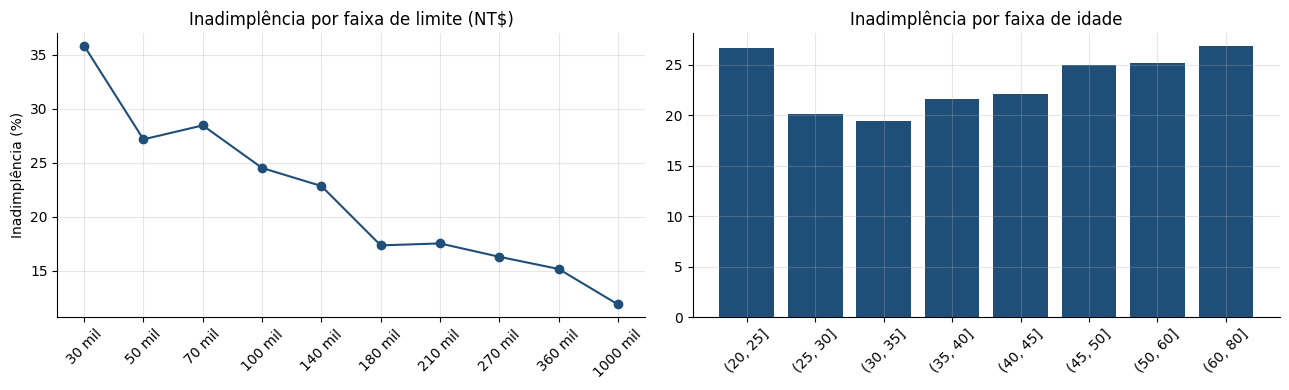

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))

# Inadimplência por faixa de limite (10 faixas com a mesma quantidade de clientes)
faixas_limite = pd.qcut(dados["limite"], 10, duplicates="drop")
taxa_limite = dados.groupby(faixas_limite, observed=True)["inadimplente"].mean() * 100
axs[0].plot(range(len(taxa_limite)), taxa_limite.values, marker="o", color=AZUL)
axs[0].set_xticks(range(len(taxa_limite)))
axs[0].set_xticklabels([f"{int(i.right / 1000)} mil" for i in taxa_limite.index], rotation=45)
axs[0].set_title("Inadimplência por faixa de limite (NT$)")
axs[0].set_ylabel("Inadimplência (%)")

# Inadimplência por faixa de idade
faixas_idade = pd.cut(dados["idade"], [20, 25, 30, 35, 40, 45, 50, 60, 80])
taxa_idade = dados.groupby(faixas_idade, observed=True)["inadimplente"].mean() * 100
axs[1].bar(taxa_idade.index.astype(str), taxa_idade.values, color=AZUL)
axs[1].set_title("Inadimplência por faixa de idade")
axs[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [10]:
# Inadimplência por escolaridade, estado civil e sexo
for coluna, rotulos in [("escolaridade", ROTULO_ESCOLARIDADE), ("estado_civil", ROTULO_ESTADO_CIVIL),
                        ("sexo", ROTULO_SEXO)]:
    tabela = dados.groupby(coluna)["inadimplente"].agg(["mean", "size"]).rename(index=rotulos)
    tabela["mean"] = (tabela["mean"] * 100).round(1)
    print(f"{coluna}:", tabela.rename(columns={"mean": "inadimplência (%)", "size": "clientes"}).to_dict("index"))

escolaridade: {'Pós-graduação': {'inadimplência (%)': 19.2, 'clientes': 10585}, 'Universidade': {'inadimplência (%)': 23.7, 'clientes': 14030}, 'Ensino médio': {'inadimplência (%)': 25.2, 'clientes': 4917}, 'Outros': {'inadimplência (%)': 7.1, 'clientes': 468}}
estado_civil: {'Casado': {'inadimplência (%)': 23.5, 'clientes': 13659}, 'Solteiro': {'inadimplência (%)': 20.9, 'clientes': 15964}, 'Outros': {'inadimplência (%)': 23.6, 'clientes': 377}}
sexo: {'Masculino': {'inadimplência (%)': 24.2, 'clientes': 11888}, 'Feminino': {'inadimplência (%)': 20.8, 'clientes': 18112}}


- **Limite:** quanto maior o limite, menor a inadimplência. O limite reflete a avaliação que o próprio banco já fez do cliente.
- **Idade:** a inadimplência é maior entre os mais jovens e volta a subir depois dos 50 anos, uma relação em formato de "U" que um modelo linear simples não captura sem tratamento. A técnica de WoE, usada mais adiante, resolve isso.
- **Perfil:** as diferenças por escolaridade, estado civil e sexo são pequenas perto das do histórico de pagamento.

### Sobre o uso de sexo e estado civil

Mesmo que existam diferenças nas taxas, **não vou usar sexo e estado civil como variáveis do modelo**. Usar características pessoais desse tipo para decidir crédito pode gerar discriminação e é vedado ou restrito em muitas regulações. Essas variáveis serão usadas apenas no final, para **auditar** se o modelo trata os grupos de forma equilibrada.

### Correlação entre as variáveis

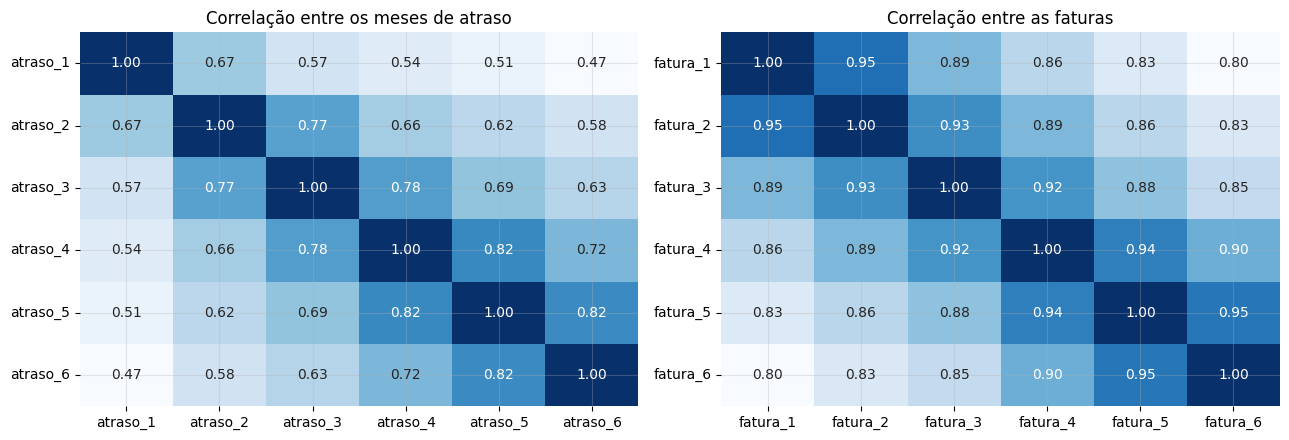

In [11]:
# Correlação entre o histórico de atraso e as faturas
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(dados[COLS_ATRASO].corr(), annot=True, fmt=".2f", cmap="Blues", ax=axs[0], cbar=False)
axs[0].set_title("Correlação entre os meses de atraso")
sns.heatmap(dados[COLS_FATURA].corr(), annot=True, fmt=".2f", cmap="Blues", ax=axs[1], cbar=False)
axs[1].set_title("Correlação entre as faturas")
plt.tight_layout()
plt.show()

As faturas de meses diferentes são **altamente correlacionadas** (acima de 0,8), assim como os meses de atraso vizinhos. Isso indica informação redundante, que vou resumir em novas variáveis na próxima etapa e controlar na seleção do scorecard.

[Voltar ao Índice](#back)

## Etapa 3. Engenharia de variáveis <a id='features'></a>

Em vez de usar só os valores brutos, vou criar variáveis que descrevem o **comportamento** do cliente, como os analistas de crédito fazem:

| Variável | O que mede |
|---|---|
| `meses_em_atraso` | Em quantos dos 6 meses o cliente atrasou |
| `maior_atraso` | O maior atraso registrado, em meses |
| `utilizacao_atual` | Fatura atual dividida pelo limite: quanto do limite está comprometido |
| `utilizacao_media` | Fatura média dos 6 meses dividida pelo limite |
| `taxa_pagamento` | Quanto o cliente pagou em relação ao que devia nas faturas anteriores |
| `variacao_fatura` | Crescimento da fatura entre abril e setembro, em relação ao limite |
| `pagamento_medio_limite` | Pagamento médio dividido pelo limite |

Um detalhe importante: o pagamento de um mês quita a fatura do mês anterior. Por isso, a taxa de pagamento compara `pagamento_1` a `pagamento_5` com `fatura_2` a `fatura_6`.

In [12]:
def criar_variaveis(df):
    """Cria as variáveis de comportamento a partir das colunas originais."""
    df = df.copy()
    df["meses_em_atraso"] = (df[COLS_ATRASO] > 0).sum(axis=1)
    df["maior_atraso"] = df[COLS_ATRASO].max(axis=1).clip(lower=0)  # Valores negativos significam sem atraso
    df["utilizacao_atual"] = (df["fatura_1"] / df["limite"]).clip(-0.5, 2)  # Limita valores extremos
    df["utilizacao_media"] = (df[COLS_FATURA].mean(axis=1) / df["limite"]).clip(-0.5, 2)

    # Taxa de pagamento: total pago dividido pelo total devido nas faturas anteriores
    pago = df[["pagamento_1", "pagamento_2", "pagamento_3", "pagamento_4", "pagamento_5"]].sum(axis=1)
    devido = df[["fatura_2", "fatura_3", "fatura_4", "fatura_5", "fatura_6"]].clip(lower=0).sum(axis=1)
    # Se não havia nada a pagar, considera que o cliente está em dia (taxa = 1)
    df["taxa_pagamento"] = np.where(devido > 0, pago / devido.replace(0, np.nan), 1).clip(0, 2)

    df["variacao_fatura"] = ((df["fatura_1"] - df["fatura_6"]) / df["limite"]).clip(-2, 2)
    df["pagamento_medio_limite"] = (df[COLS_PAGAMENTO].mean(axis=1) / df["limite"]).clip(0, 1)
    return df


dados = criar_variaveis(dados)
NOVAS = ["meses_em_atraso", "maior_atraso", "utilizacao_atual", "utilizacao_media",
         "taxa_pagamento", "variacao_fatura", "pagamento_medio_limite"]
dados[NOVAS].describe().round(2)

,meses_em_atraso,maior_atraso,utilizacao_atual,utilizacao_media,taxa_pagamento,variacao_fatura,pagamento_medio_limite
count,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00
mean,0.83,0.68,0.42,0.37,0.40,0.10,0.04
std,1.55,1.07,0.40,0.35,0.43,0.30,0.05
min,0.00,0.00,-0.50,-0.23,0.00,-1.83,0.00
25%,0.00,0.00,0.02,0.03,0.05,-0.03,0.01
50%,0.00,0.00,0.31,0.28,0.12,0.01,0.03
75%,1.00,2.00,0.83,0.69,0.94,0.18,0.04
max,6.00,8.00,2.00,2.00,2.00,2.00,1.00


In [13]:
# Inadimplência pela quantidade de meses em atraso: a nova variável separa muito bem os clientes
tabela = dados.groupby("meses_em_atraso")["inadimplente"].agg(["mean", "size"])
tabela["mean"] = (tabela["mean"] * 100).round(1)
tabela.rename(columns={"mean": "inadimplência (%)", "size": "clientes"})

,inadimplência (%),clientes
meses_em_atraso,,
0,11.7,19931
1,29.8,4426
2,38.8,1899
3,50.9,1154
4,57.3,951
5,57.4,298
6,70.3,1341


A variável `meses_em_atraso` mostra uma relação muito clara: a inadimplência sobe de cerca de 12%, para quem nunca atrasou, até 70%, para quem atrasou nos 6 meses.

### Variáveis que vão para os modelos

Uso todas as variáveis de comportamento, o limite, a idade e a escolaridade. **Sexo e estado civil ficam de fora**, como explicado na análise exploratória.

In [14]:
VARIAVEIS = (["limite", "idade", "escolaridade"] + COLS_ATRASO + COLS_FATURA + COLS_PAGAMENTO + NOVAS)
ALVO = "inadimplente"
print(f"Total de variáveis candidatas: {len(VARIAVEIS)}")

Total de variáveis candidatas: 28


[Voltar ao Índice](#back)

## Etapa 4. Divisão dos dados <a id='split'></a>

Divido os dados em três partes, mantendo a mesma proporção de inadimplentes em cada uma (estratificação):

- **Treino (60%):** para ajustar os modelos
- **Validação (20%):** para escolher hiperparâmetros e comparar modelos
- **Teste (20%):** usado **uma única vez**, no final, para a avaliação definitiva

In [15]:
# Primeiro separa o teste (20%) e depois divide o restante em treino (60%) e validação (20%)
treino_val, teste = train_test_split(dados, test_size=0.2, stratify=dados[ALVO], random_state=SEMENTE)
treino, validacao = train_test_split(treino_val, test_size=0.25, stratify=treino_val[ALVO], random_state=SEMENTE)

for nome, parte in [("Treino", treino), ("Validação", validacao), ("Teste", teste)]:
    print(f"{nome:10s}: {len(parte):6,} clientes | inadimplência: {parte[ALVO].mean():.1%}".replace(",", "."))

Treino    : 18.000 clientes | inadimplência: 22.1%
Validação :  6.000 clientes | inadimplência: 22.1%
Teste     :  6.000 clientes | inadimplência: 22.1%


[Voltar ao Índice](#back)

## Etapa 5. Poder preditivo das variáveis: WoE e IV <a id='woe'></a>

No mercado de crédito, o poder de cada variável é medido com duas ferramentas:

- **WoE (Weight of Evidence):** divido a variável em faixas e calculo, para cada faixa, `ln(% de bons / % de maus)`. Um WoE positivo indica uma faixa de **menor risco**; negativo, de **maior risco**.
- **IV (Information Value):** resume o poder preditivo da variável inteira, somando a diferença entre bons e maus ponderada pelo WoE.

| IV | Poder preditivo |
|---|---|
| Menor que 0,02 | Inútil |
| 0,02 a 0,1 | Fraco |
| 0,1 a 0,3 | Médio |
| 0,3 a 0,5 | Forte |
| Maior que 0,5 | Muito forte (vale checar se não há vazamento) |

Uma vantagem do WoE é que ele transforma relações não lineares, como a da idade em formato de "U", em relações lineares, ideais para a Regressão Logística. Todas as faixas são calculadas **só com os dados de treino**.

In [16]:
def criar_faixas(serie, n_faixas=10):
    """Define os limites das faixas de uma variável a partir dos dados de treino."""
    if serie.nunique() <= n_faixas:  # Variáveis com poucos valores: cada valor é uma faixa
        valores = np.sort(serie.unique())
        limites = list((valores[:-1] + valores[1:]) / 2)  # Pontos médios entre valores vizinhos
    else:  # Variáveis contínuas: faixas com a mesma quantidade de clientes (quantis)
        limites = list(np.unique(np.quantile(serie, np.linspace(0, 1, n_faixas + 1)[1:-1])))
    return [-np.inf] + limites + [np.inf]


def tabela_woe(serie, alvo, limites):
    """Calcula a quantidade de clientes, a inadimplência e o WoE de cada faixa."""
    faixas = pd.cut(serie, limites)
    t = pd.DataFrame({"faixa": faixas, "mau": alvo}).groupby("faixa", observed=False)["mau"].agg(["size", "sum"])
    t.columns = ["clientes", "maus"]
    t["bons"] = t["clientes"] - t["maus"]
    # Soma 0,5 para evitar divisão por zero em faixas sem bons ou sem maus
    pct_bons = (t["bons"] + 0.5) / (t["bons"].sum() + 0.5)
    pct_maus = (t["maus"] + 0.5) / (t["maus"].sum() + 0.5)
    t["inadimplencia"] = t["maus"] / t["clientes"]
    t["woe"] = np.log(pct_bons / pct_maus)
    t["iv"] = (pct_bons - pct_maus) * t["woe"]
    return t


# Calcula as faixas, o WoE e o IV de cada variável usando só o treino
LIMITES, TABELAS_WOE, iv = {}, {}, {}
for var in VARIAVEIS:
    LIMITES[var] = criar_faixas(treino[var])
    TABELAS_WOE[var] = tabela_woe(treino[var], treino[ALVO], LIMITES[var])
    iv[var] = TABELAS_WOE[var]["iv"].sum()

iv = pd.Series(iv).sort_values(ascending=False)
classificacao = pd.cut(iv, [-np.inf, 0.02, 0.1, 0.3, 0.5, np.inf],
                       labels=["Inútil", "Fraco", "Médio", "Forte", "Muito forte"])
pd.DataFrame({"IV": iv.round(3), "Poder preditivo": classificacao})

,IV,Poder preditivo
atraso_1,0.905,Muito forte
meses_em_atraso,0.888,Muito forte
maior_atraso,0.808,Muito forte
atraso_2,0.546,Muito forte
atraso_3,0.416,Forte
atraso_4,0.354,Forte
atraso_5,0.333,Forte
atraso_6,0.287,Médio
limite,0.201,Médio
pagamento_1,0.178,Médio


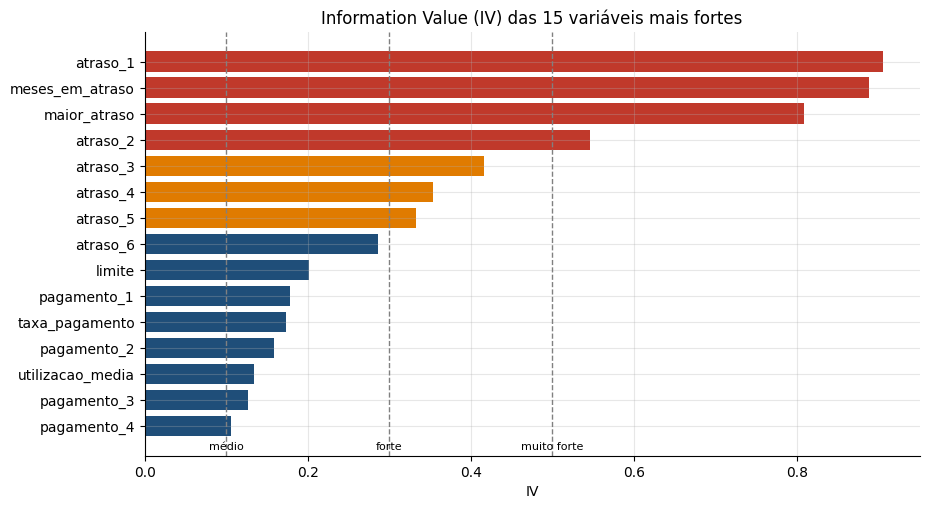

In [17]:
# Gráfico do IV das 15 variáveis mais fortes
top = iv.head(15).sort_values()
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(top.index, top.values, color=[VERMELHO if v > 0.5 else LARANJA if v > 0.3 else AZUL for v in top.values])
for limite, texto in [(0.1, "médio"), (0.3, "forte"), (0.5, "muito forte")]:
    ax.axvline(limite, color="gray", ls="--", lw=1)
    ax.text(limite, -0.9, texto, fontsize=8, ha="center")
ax.set_title("Information Value (IV) das 15 variáveis mais fortes")
ax.set_xlabel("IV")
plt.show()

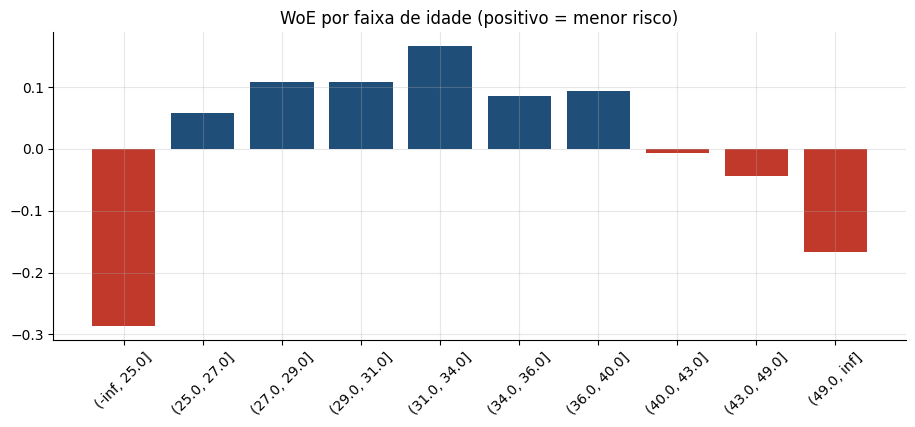

In [18]:
# WoE da idade: a relação em "U" vista na análise exploratória
t = TABELAS_WOE["idade"]
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(t.index.astype(str), t["woe"], color=[AZUL if w > 0 else VERMELHO for w in t["woe"]])
ax.set_title("WoE por faixa de idade (positivo = menor risco)")
ax.tick_params(axis="x", rotation=45)
plt.show()

### Conclusões

- O **histórico de pagamento domina**: `atraso_1` (IV de 0,91), `meses_em_atraso` (0,89) e `maior_atraso` (0,81) são muito fortes. Um IV acima de 0,5 pode indicar vazamento de informação, mas aqui faz sentido: o comportamento recente de pagamento é o que melhor antecipa a inadimplência, e todas essas informações são anteriores ao mês previsto.
- O **limite** e os **pagamentos** têm poder médio.
- Os **valores das faturas**, sozinhos, são inúteis (IV abaixo de 0,02). O que importa é a fatura **em relação ao limite** (a utilização) e quanto o cliente paga dela, por isso as variáveis criadas na Etapa 3 têm IV maior que as originais.
- A **idade** tem poder fraco, e o WoE confirma o formato em "U": as faixas até 25 anos e acima de 49 anos têm WoE negativo (mais risco), e as faixas intermediárias, positivo.

[Voltar ao Índice](#back)

## Etapa 6. Modelo 1: Scorecard com Regressão Logística <a id='scorecard'></a>

O **scorecard** é o modelo mais usado em bancos. Ele é construído assim:

1. Cada variável é substituída pelo **WoE** da faixa em que o cliente está.
2. Uma **Regressão Logística** é ajustada sobre essas variáveis.
3. Os coeficientes são convertidos em **pontos**: o score final é a soma dos pontos de cada característica do cliente.

A grande vantagem é a **transparência**: é possível explicar a qualquer cliente ou regulador por que ele recebeu aquele score.

### Seleção das variáveis

Seleciono as variáveis em três passos, como é feito na prática:

1. Mantenho só as variáveis com **IV de pelo menos 0,02**.
2. Quando dois WoE têm **correlação acima de 0,7**, mantenho só o de maior IV, porque variáveis redundantes deixam os coeficientes instáveis.
3. Depois de ajustar a Regressão Logística, removo, uma a uma, as variáveis com **coeficiente positivo**. Como o WoE é positivo nas faixas de menor risco, todo coeficiente deve ser negativo; um coeficiente positivo indica que a variável está "brigando" com outra correlacionada e tornaria o score incoerente.

In [19]:
def aplicar_woe(df, variaveis):
    """Substitui cada variável pelo WoE da faixa correspondente."""
    resultado = pd.DataFrame(index=df.index)
    for var in variaveis:
        faixas = pd.cut(df[var], LIMITES[var])
        resultado[var] = faixas.map(TABELAS_WOE[var]["woe"]).astype(float)
    return resultado


# 1) Mantém as variáveis com IV de pelo menos 0,02, da mais forte para a mais fraca
candidatas = iv[iv >= 0.02].index.tolist()
woe_treino = aplicar_woe(treino, candidatas)

# 2) Remove variáveis muito correlacionadas, mantendo a de maior IV
selecionadas = []
for var in candidatas:
    if all(abs(woe_treino[var].corr(woe_treino[s])) < 0.7 for s in selecionadas):
        selecionadas.append(var)

print(f"Variáveis com IV >= 0,02: {len(candidatas)}")
print(f"Variáveis selecionadas para o scorecard ({len(selecionadas)}): {selecionadas}")

Variáveis com IV >= 0,02: 23
Variáveis selecionadas para o scorecard (21): ['atraso_1', 'maior_atraso', 'atraso_2', 'atraso_3', 'atraso_4', 'atraso_5', 'atraso_6', 'limite', 'pagamento_1', 'taxa_pagamento', 'pagamento_2', 'utilizacao_media', 'pagamento_3', 'pagamento_4', 'pagamento_6', 'pagamento_5', 'variacao_fatura', 'pagamento_medio_limite', 'escolaridade', 'fatura_6', 'idade']


In [20]:
# Aplica o WoE em treino, validação e teste (sempre com as faixas calculadas no treino)
X_treino_woe = aplicar_woe(treino, selecionadas)
X_val_woe = aplicar_woe(validacao, selecionadas)
X_teste_woe = aplicar_woe(teste, selecionadas)

# Ajusta a Regressão Logística e remove, uma a uma, as variáveis com coeficiente positivo
removidas = []
while True:
    logistica = LogisticRegression(max_iter=1000)
    logistica.fit(X_treino_woe[selecionadas], treino[ALVO])
    coeficientes = pd.Series(logistica.coef_[0], index=selecionadas)
    if coeficientes.max() <= 0:  # Todos negativos: o scorecard está coerente
        break
    pior = coeficientes.idxmax()  # Variável com o maior coeficiente positivo
    selecionadas.remove(pior)
    removidas.append(pior)

# Mantém em treino, validação e teste só as variáveis finais
X_treino_woe, X_val_woe, X_teste_woe = (X[selecionadas] for X in (X_treino_woe, X_val_woe, X_teste_woe))

pd_scorecard_val = logistica.predict_proba(X_val_woe)[:, 1]  # Probabilidade de inadimplência
print(f"Removidas por coeficiente positivo: {removidas}")
print(f"Variáveis finais do scorecard ({len(selecionadas)}): {selecionadas}")
print(f"AUC na validação: {roc_auc_score(validacao[ALVO], pd_scorecard_val):.3f}")
print("\nCoeficientes finais:")
print(coeficientes.round(3).to_string())

Removidas por coeficiente positivo: ['fatura_6', 'atraso_2']
Variáveis finais do scorecard (19): ['atraso_1', 'maior_atraso', 'atraso_3', 'atraso_4', 'atraso_5', 'atraso_6', 'limite', 'pagamento_1', 'taxa_pagamento', 'pagamento_2', 'utilizacao_media', 'pagamento_3', 'pagamento_4', 'pagamento_6', 'pagamento_5', 'variacao_fatura', 'pagamento_medio_limite', 'escolaridade', 'idade']


AUC na validação: 0.767

Coeficientes finais:
atraso_1                 -0.628
maior_atraso             -0.291
atraso_3                 -0.086
atraso_4                 -0.012
atraso_5                 -0.131
atraso_6                 -0.077
limite                   -0.252
pagamento_1              -0.100
taxa_pagamento           -0.186
pagamento_2              -0.132
utilizacao_media         -0.293
pagamento_3              -0.192
pagamento_4              -0.095
pagamento_6              -0.179
pagamento_5              -0.118
variacao_fatura          -0.224
pagamento_medio_limite   -0.202
escolaridade             -0.375
idade                    -0.126


### Conclusões

- O filtro de correlação removeu variáveis redundantes, como `meses_em_atraso`, muito correlacionada com `atraso_1`.
- O filtro de sinal removeu `fatura_6` e `atraso_2`, que tinham coeficiente positivo por causa da correlação com outras variáveis do modelo.
- O scorecard final tem **19 variáveis, todas com coeficiente negativo**, e AUC de 0,767 na validação. A variável de maior peso é `atraso_1`, a situação de pagamento mais recente.

### Convertendo em pontos

Uso a escala mais comum do mercado:

- **600 pontos** correspondem a uma chance de 50 bons para cada mau
- **PDO = 20**: a cada 20 pontos a mais, a chance de o cliente ser bom **dobra**

Assim, **quanto maior o score, menor o risco**.

In [21]:
# Parâmetros da escala do score
SCORE_BASE, CHANCE_BASE, PDO = 600, 50, 20
fator = PDO / np.log(2)  # Pontos por unidade de log da chance
deslocamento = SCORE_BASE - fator * np.log(CHANCE_BASE)
n_vars = len(selecionadas)


def calcular_score(woe_df):
    """Score = deslocamento - fator x (intercepto + soma de coeficiente x WoE)."""
    logit = logistica.intercept_[0] + woe_df.values @ logistica.coef_[0]
    return deslocamento - fator * logit


# Tabela de pontos: quantos pontos cada faixa de cada variável vale
linhas = []
for var, coef in zip(selecionadas, logistica.coef_[0]):
    t = TABELAS_WOE[var]
    for faixa, woe in t["woe"].items():
        pontos = -fator * coef * woe - fator * logistica.intercept_[0] / n_vars + deslocamento / n_vars
        linhas.append({"variável": var, "faixa": str(faixa), "clientes no treino": int(t.loc[faixa, "clientes"]),
                       "inadimplência (%)": round(t.loc[faixa, "inadimplencia"] * 100, 1), "pontos": round(pontos)})
tabela_pontos = pd.DataFrame(linhas)

# Mostra os pontos de duas variáveis como exemplo
tabela_pontos[tabela_pontos["variável"].isin(["atraso_1", "limite"])]

,variável,faixa,clientes no treino,inadimplência (%),pontos
0,atraso_1,"(-inf, -1.0]",5039,15.2,36
1,atraso_1,"(-1.0, 0.0]",8807,12.6,40
2,atraso_1,"(0.0, 1.0]",2269,34.4,16
3,atraso_1,"(1.0, 2.0]",1618,69.5,-10
4,atraso_1,"(2.0, inf]",267,73.8,-14
44,limite,"(-inf, 30000.0]",2439,36.7,22
45,limite,"(30000.0, 50000.0]",2171,27.4,25
46,limite,"(50000.0, 70000.0]",934,28.8,25
47,limite,"(70000.0, 100000.0]",1927,24.4,27
48,limite,"(100000.0, 140000.0]",1695,22.8,27


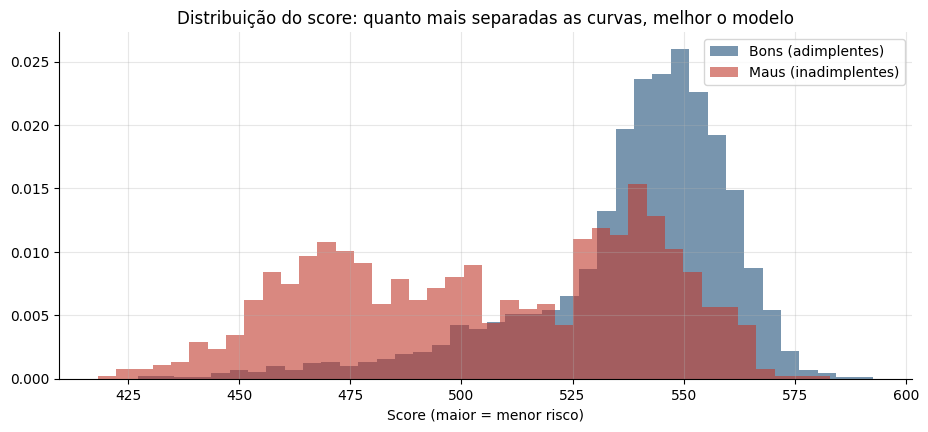

In [22]:
# Distribuição do score de bons e maus clientes na validação
score_val = calcular_score(X_val_woe)
fig, ax = plt.subplots()
ax.hist(score_val[validacao[ALVO] == 0], bins=40, alpha=0.6, color=AZUL, label="Bons (adimplentes)", density=True)
ax.hist(score_val[validacao[ALVO] == 1], bins=40, alpha=0.6, color=VERMELHO, label="Maus (inadimplentes)", density=True)
ax.set_title("Distribuição do score: quanto mais separadas as curvas, melhor o modelo")
ax.set_xlabel("Score (maior = menor risco)")
ax.legend()
plt.show()

[Voltar ao Índice](#back)

## Etapa 7. Modelo 2: LightGBM <a id='lgbm'></a>

O **LightGBM** combina centenas de árvores de decisão. Ele captura relações não lineares e interações entre variáveis automaticamente, sem precisar de WoE, mas é menos transparente que o scorecard.

Uso a validação para o **early stopping**: o modelo para de adicionar árvores quando o desempenho na validação deixa de melhorar, o que evita overfitting.

In [23]:
# Hiperparâmetros conservadores: árvores rasas, aprendizado lento e regularização
lgbm = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.02, num_leaves=15, min_child_samples=50,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                          random_state=SEMENTE, verbose=-1)
lgbm.fit(treino[VARIAVEIS], treino[ALVO],
         eval_set=[(validacao[VARIAVEIS], validacao[ALVO])], eval_metric="auc",
         callbacks=[lgb.early_stopping(100, verbose=False)])

pd_lgbm_val = lgbm.predict_proba(validacao[VARIAVEIS])[:, 1]
print(f"Árvores usadas: {lgbm.best_iteration_}")
print(f"AUC na validação: {roc_auc_score(validacao[ALVO], pd_lgbm_val):.3f}")

Árvores usadas: 333
AUC na validação: 0.789


[Voltar ao Índice](#back)

## Etapa 8. Comparação dos modelos <a id='comparison'></a>

### Métricas usadas em crédito

| Métrica | O que mede | Referência |
|---|---|---|
| **AUC** | Probabilidade de o modelo dar mais risco a um mau do que a um bom | 0,5 = aleatório, 1 = perfeito |
| **Gini** | `2 x AUC - 1`, a forma como o mercado de crédito costuma reportar | Acima de 0,4 já é útil em crédito |
| **KS** | Maior distância entre as distribuições acumuladas de bons e maus | Acima de 0,3 é considerado bom |
| **Brier** | Erro quadrático médio das probabilidades: mede a calibração | Quanto menor, melhor |

Agora uso o **conjunto de teste**, pela primeira e única vez.

In [24]:
def avaliar(y, pd_prevista):
    """Calcula AUC, Gini, KS e Brier."""
    auc = roc_auc_score(y, pd_prevista)
    fpr, tpr, _ = roc_curve(y, pd_prevista)
    return {"AUC": auc, "Gini": 2 * auc - 1, "KS": np.max(tpr - fpr), "Brier": brier_score_loss(y, pd_prevista)}


# Probabilidades no teste
pd_scorecard_teste = logistica.predict_proba(X_teste_woe)[:, 1]
pd_lgbm_teste = lgbm.predict_proba(teste[VARIAVEIS])[:, 1]

resultados = pd.DataFrame({
    ("Scorecard", "Validação"): avaliar(validacao[ALVO], pd_scorecard_val),
    ("Scorecard", "Teste"): avaliar(teste[ALVO], pd_scorecard_teste),
    ("LightGBM", "Validação"): avaliar(validacao[ALVO], pd_lgbm_val),
    ("LightGBM", "Teste"): avaliar(teste[ALVO], pd_lgbm_teste),
}).T.round(3)
resultados

AUC   Gini     KS  Brier
Scorecard Validação  0.767  0.533  0.410  0.137
          Teste      0.763  0.526  0.395  0.139
LightGBM  Validação  0.789  0.578  0.438  0.133
          Teste      0.782  0.564  0.430  0.134

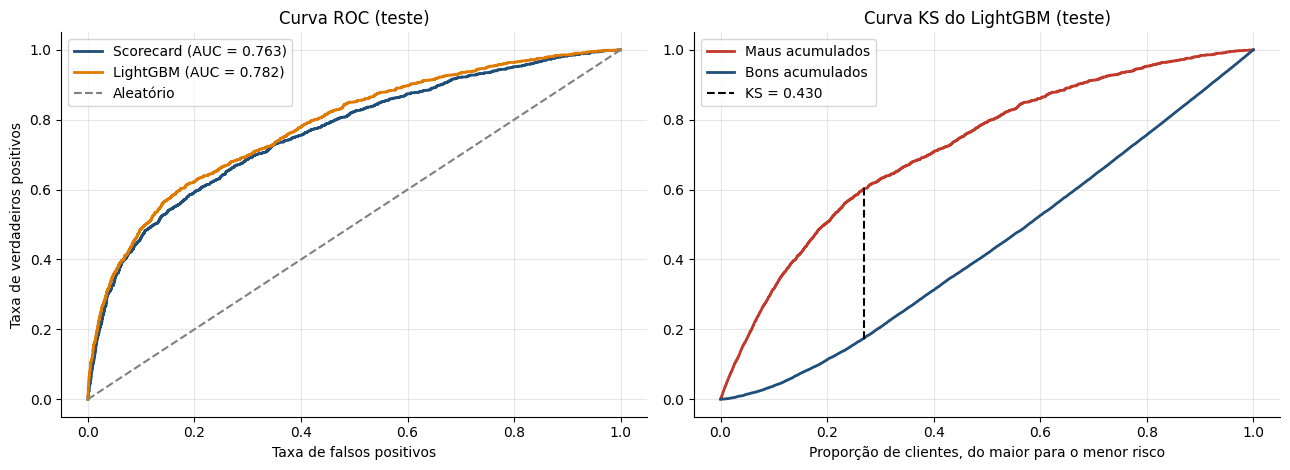

In [25]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))

# Curva ROC dos dois modelos no teste
for nome, pd_prev, cor in [("Scorecard", pd_scorecard_teste, AZUL), ("LightGBM", pd_lgbm_teste, LARANJA)]:
    fpr, tpr, _ = roc_curve(teste[ALVO], pd_prev)
    axs[0].plot(fpr, tpr, color=cor, lw=2, label=f"{nome} (AUC = {roc_auc_score(teste[ALVO], pd_prev):.3f})")
axs[0].plot([0, 1], [0, 1], color="gray", ls="--", label="Aleatório")
axs[0].set_title("Curva ROC (teste)")
axs[0].set_xlabel("Taxa de falsos positivos")
axs[0].set_ylabel("Taxa de verdadeiros positivos")
axs[0].legend()

# Curva KS do LightGBM: distribuição acumulada de bons e maus por faixa de risco
ordem = np.argsort(-pd_lgbm_teste)  # Do maior para o menor risco
y_ord = teste[ALVO].values[ordem]
acum_maus = np.cumsum(y_ord) / y_ord.sum()
acum_bons = np.cumsum(1 - y_ord) / (1 - y_ord).sum()
populacao = np.arange(1, len(y_ord) + 1) / len(y_ord)
i_ks = np.argmax(acum_maus - acum_bons)
axs[1].plot(populacao, acum_maus, color=VERMELHO, lw=2, label="Maus acumulados")
axs[1].plot(populacao, acum_bons, color=AZUL, lw=2, label="Bons acumulados")
axs[1].vlines(populacao[i_ks], acum_bons[i_ks], acum_maus[i_ks], color="black", ls="--",
              label=f"KS = {acum_maus[i_ks] - acum_bons[i_ks]:.3f}")
axs[1].set_title("Curva KS do LightGBM (teste)")
axs[1].set_xlabel("Proporção de clientes, do maior para o menor risco")
axs[1].legend()
plt.tight_layout()
plt.show()

### Calibração

Em crédito, não basta ordenar bem os clientes: a **probabilidade prevista precisa corresponder à realidade**. Se o modelo diz 30% para um grupo de clientes, cerca de 30% deles devem ficar inadimplentes. Isso é essencial para calcular perdas esperadas e provisões.

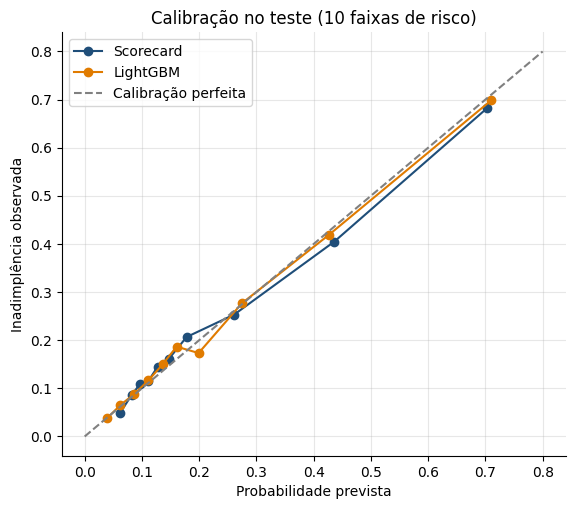

In [26]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for nome, pd_prev, cor in [("Scorecard", pd_scorecard_teste, AZUL), ("LightGBM", pd_lgbm_teste, LARANJA)]:
    real, previsto = calibration_curve(teste[ALVO], pd_prev, n_bins=10, strategy="quantile")
    ax.plot(previsto, real, marker="o", color=cor, label=nome)
ax.plot([0, 0.8], [0, 0.8], color="gray", ls="--", label="Calibração perfeita")
ax.set_title("Calibração no teste (10 faixas de risco)")
ax.set_xlabel("Probabilidade prevista")
ax.set_ylabel("Inadimplência observada")
ax.legend()
plt.show()

### Conclusões

- O **LightGBM é melhor em todas as métricas**: no teste, AUC de 0,782 contra 0,763, Gini de 0,56 contra 0,53 e KS de 0,43 contra 0,40. Os dois superam com folga as referências do mercado (Gini acima de 0,4 e KS acima de 0,3).
- A diferença entre validação e teste é pequena nos dois modelos, ou seja, **não há overfitting**.
- Os **dois modelos estão bem calibrados**: as curvas ficam próximas da diagonal, e o Brier é parecido (0,134 e 0,139). As probabilidades podem ser usadas diretamente para estimar perdas.
- **Escolha:** uso o **LightGBM** na política de crédito, porque ele ordena melhor os clientes, e o SHAP, na próxima etapa, compensa a menor transparência. O scorecard continua valioso como **modelo desafiante** e nos casos em que a regulação exige uma explicação por pontos.

[Voltar ao Índice](#back)

## Etapa 9. Explicabilidade com SHAP <a id='shap'></a>

O **SHAP** mostra quanto cada variável empurrou a previsão de cada cliente para cima (mais risco) ou para baixo (menos risco). Isso torna o LightGBM explicável, uma exigência cada vez mais comum em decisões de crédito.

No gráfico abaixo, cada ponto é um cliente. A cor indica o valor da variável (vermelho = alto, azul = baixo) e a posição horizontal indica o impacto na previsão (à direita = mais risco).

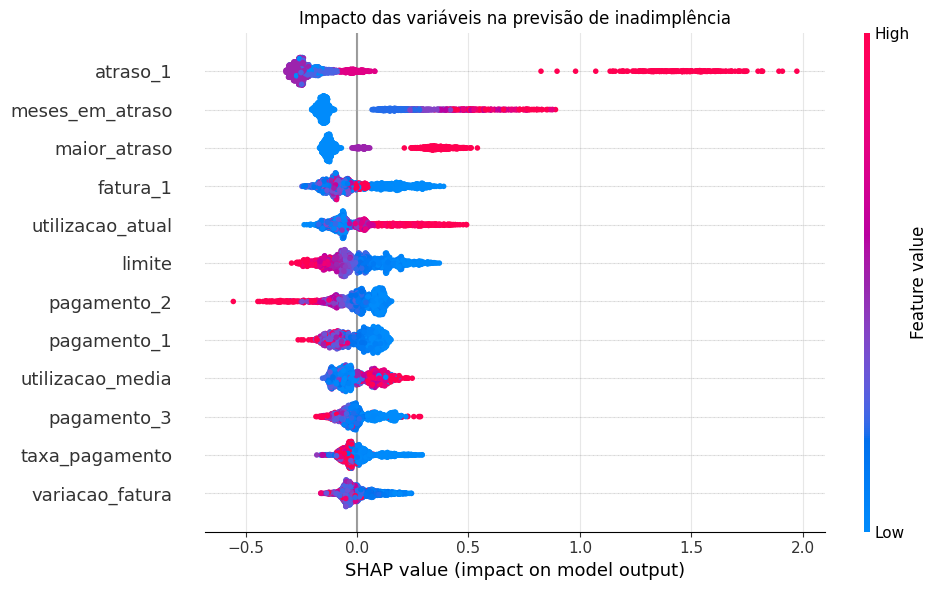

In [27]:
# Calcula os valores SHAP para uma amostra de 2.000 clientes do teste
amostra = teste[VARIAVEIS].sample(2000, random_state=SEMENTE)
explicador = shap.TreeExplainer(lgbm)
valores_shap = explicador.shap_values(amostra)
if isinstance(valores_shap, list):  # Em algumas versões, o SHAP devolve uma lista com as duas classes
    valores_shap = valores_shap[1]

shap.summary_plot(valores_shap, amostra, max_display=12, show=False, plot_size=(10, 6))
plt.title("Impacto das variáveis na previsão de inadimplência")
plt.tight_layout()
plt.show()

In [28]:
# Importância média de cada variável: média do valor absoluto do SHAP
importancia = pd.Series(np.abs(valores_shap).mean(axis=0), index=VARIAVEIS).sort_values(ascending=False)
(importancia.head(10) / importancia.sum() * 100).round(1).rename("participação na explicação (%)")

atraso_1            18.8
meses_em_atraso     11.9
maior_atraso        10.4
fatura_1             6.6
utilizacao_atual     5.8
limite               5.8
pagamento_2          4.5
pagamento_1          4.3
utilizacao_media     4.2
pagamento_3          3.3
Name: participação na explicação (%), dtype: float64

### Conclusões

- As três variáveis de **histórico de atraso** (`atraso_1`, `meses_em_atraso` e `maior_atraso`) respondem por cerca de 40% da explicação. Quanto maior o atraso, maior o risco.
- **Limite alto reduz o risco**: o limite reflete a avaliação que o banco já fez do cliente.
- **Utilização alta aumenta o risco**: clientes que comprometem grande parte do limite estão mais pressionados financeiramente.
- Com a utilização já no modelo, **faturas maiores em valor absoluto** aparecem associadas a menor risco, provavelmente por refletirem clientes de maior renda.
- O modelo aprendeu relações que fazem sentido para o negócio, o que aumenta a confiança em usá-lo.

[Voltar ao Índice](#back)

## Etapa 10. Faixas de risco e política de crédito <a id='policy'></a>

Um modelo só gera valor quando vira **decisão**. Nesta etapa, transformo a probabilidade de inadimplência em:

1. **Faixas de risco (ratings)** de A a E, fáceis de usar pelas áreas de negócio
2. Uma **simulação de política de crédito**: o que acontece se o banco restringir o crédito dos clientes mais arriscados

Uso o modelo escolhido na comparação. As faixas são definidas com os quintis do **treino** e aplicadas no **teste**.

In [29]:
# Modelo escolhido para a política (definido pela comparação da Etapa 8)
pd_treino_final = lgbm.predict_proba(treino[VARIAVEIS])[:, 1]
pd_teste_final = pd_lgbm_teste

# Limites das faixas: quintis da probabilidade no treino (20% dos clientes em cada faixa)
limites_rating = np.quantile(pd_treino_final, [0.2, 0.4, 0.6, 0.8])
RATINGS = ["A", "B", "C", "D", "E"]  # A = menor risco, E = maior risco


def rating(pd_prevista):
    return pd.Categorical(np.array(RATINGS)[np.searchsorted(limites_rating, pd_prevista)], categories=RATINGS)


teste_final = teste.assign(pd_prevista=pd_teste_final, rating=rating(pd_teste_final))
tabela_rating = teste_final.groupby("rating", observed=False).agg(
    clientes=("inadimplente", "size"),
    pd_media_prevista=("pd_prevista", "mean"),
    inadimplencia_real=("inadimplente", "mean"),
)
tabela_rating["% dos clientes"] = tabela_rating["clientes"] / len(teste_final) * 100
tabela_rating["% dos inadimplentes"] = (teste_final.groupby("rating", observed=False)["inadimplente"].sum()
                                         / teste_final["inadimplente"].sum() * 100)
for c in ["pd_media_prevista", "inadimplencia_real"]:
    tabela_rating[c] = tabela_rating[c] * 100
tabela_rating.round(1)

,clientes,pd_media_prevista,inadimplencia_real,% dos clientes,% dos inadimplentes
rating,,,,,
A,1206,5.1,5.2,20.1,4.7
B,1210,9.9,10.1,20.2,9.2
C,1196,14.9,17.1,19.9,15.4
D,1199,23.8,22.4,20.0,20.2
E,1189,57.0,56.3,19.8,50.4


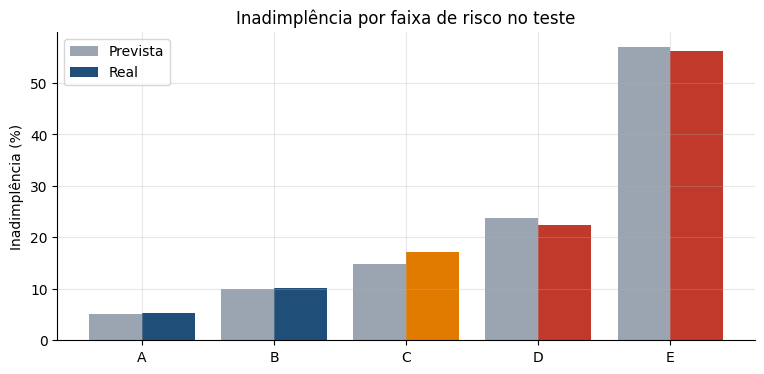

In [30]:
# Gráfico: inadimplência prevista e real em cada faixa
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(RATINGS))
ax.bar(x - 0.2, tabela_rating["pd_media_prevista"], 0.4, color=CINZA, label="Prevista")
ax.bar(x + 0.2, tabela_rating["inadimplencia_real"], 0.4, color=[AZUL, AZUL, LARANJA, VERMELHO, VERMELHO],
       label="Real")
ax.set_xticks(x)
ax.set_xticklabels(RATINGS)
ax.set_title("Inadimplência por faixa de risco no teste")
ax.set_ylabel("Inadimplência (%)")
ax.legend()
plt.show()

### Simulação da política de crédito

Simulo várias políticas: restringir o crédito dos 5%, 10%, ..., 40% de clientes com maior probabilidade de inadimplência. Para cada uma, calculo:

- **Inadimplência dos clientes mantidos:** como fica a carteira depois da restrição
- **Inadimplentes evitados:** quantos dos maus clientes a política identificou
- **Saldo em risco evitado:** quanto do saldo devedor (fatura atual) dos inadimplentes estava com os clientes restringidos
- **Bons clientes afetados:** o custo da política, porque cada bom cliente restringido é receita perdida

In [31]:
saldo = teste_final["fatura_1"].clip(lower=0)  # Saldo devedor atual (exposição)
maus = teste_final["inadimplente"] == 1
ordem_risco = teste_final["pd_prevista"].rank(ascending=False, method="first")  # 1 = maior risco

linhas = []
for corte in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40]:
    restritos = ordem_risco <= corte * len(teste_final)
    linhas.append({
        "% restringido": corte * 100,
        "inadimplência dos mantidos (%)": teste_final.loc[~restritos, "inadimplente"].mean() * 100,
        "inadimplentes evitados (%)": (restritos & maus).sum() / maus.sum() * 100,
        "saldo em risco evitado (%)": saldo[restritos & maus].sum() / saldo[maus].sum() * 100,
        "bons clientes afetados (%)": (restritos & ~maus).sum() / (~maus).sum() * 100,
    })
politica = pd.DataFrame(linhas).set_index("% restringido").round(1)
politica

,inadimplência dos mantidos (%),inadimplentes evitados (%),saldo em risco evitado (%),bons clientes afetados (%)
% restringido,,,,
5.0,19.2,17.5,21.0,1.5
10.0,16.8,31.6,43.4,3.9
15.0,15.2,41.7,48.8,7.4
20.0,13.7,50.5,53.2,11.3
25.0,12.4,58.0,58.1,15.6
30.0,11.7,63.0,59.7,20.6
35.0,11.3,66.9,63.8,25.9
40.0,10.8,70.8,68.2,31.2


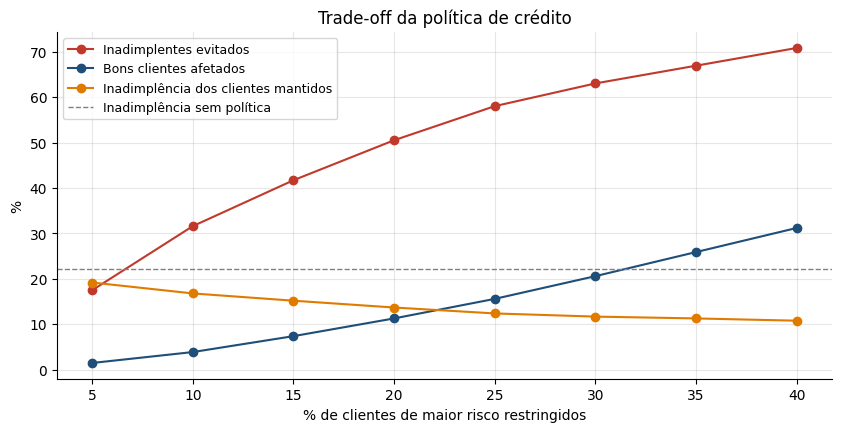

In [32]:
# Gráfico do trade-off: inadimplentes evitados x bons clientes afetados
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(politica.index, politica["inadimplentes evitados (%)"], marker="o", color=VERMELHO, label="Inadimplentes evitados")
ax.plot(politica.index, politica["bons clientes afetados (%)"], marker="o", color=AZUL, label="Bons clientes afetados")
ax.plot(politica.index, politica["inadimplência dos mantidos (%)"], marker="o", color=LARANJA,
        label="Inadimplência dos clientes mantidos")
ax.axhline(teste_final["inadimplente"].mean() * 100, color="gray", ls="--", lw=1, label="Inadimplência sem política")
ax.set_title("Trade-off da política de crédito")
ax.set_xlabel("% de clientes de maior risco restringidos")
ax.set_ylabel("%")
ax.legend(fontsize=9)
plt.show()

### Conclusões

- **As faixas ordenam muito bem o risco**: a inadimplência real vai de **5% na faixa A a 56% na faixa E**, e a prevista fica muito próxima da real em todas as faixas.
- A **faixa E**, com 20% dos clientes, concentra **metade de todos os inadimplentes**.
- Restringindo o crédito dos **20% de maior risco**, a inadimplência da carteira mantida cai de **22,1% para 13,7%**. A política evita **50,5% dos inadimplentes** e **53,2% do saldo em risco**, ao custo de afetar **11,3% dos bons clientes**.
- O ponto de corte ideal depende da margem que cada bom cliente gera e da perda que cada mau causa. Na prática, "restringir" não precisa significar cancelar: pode ser **reduzir o limite**, suspender aumentos ou **priorizar a cobrança**, o que diminui o custo sobre os bons clientes.

**Recomendação:** clientes da **faixa E** recebem redução de limite e entram na régua de cobrança preventiva; a **faixa D** fica em monitoramento; as faixas **A e B** são candidatas a aumento de limite.

[Voltar ao Índice](#back)

## Etapa 11. Estabilidade e equidade do modelo <a id='monitoring'></a>

### Estabilidade: PSI

Depois de implantado, um modelo de crédito precisa ser monitorado. A métrica padrão é o **PSI (Population Stability Index)**, que compara a distribuição dos scores entre duas populações, por exemplo, a do desenvolvimento e a do mês atual.

| PSI | Interpretação |
|---|---|
| Menor que 0,1 | Estável |
| 0,1 a 0,25 | Atenção: mudança moderada |
| Maior que 0,25 | Mudança significativa: rever o modelo |

In [33]:
def psi(referencia, atual, n_faixas=10):
    """Population Stability Index entre duas distribuições de probabilidade."""
    limites = np.quantile(referencia, np.linspace(0, 1, n_faixas + 1))
    limites[0], limites[-1] = -np.inf, np.inf
    pct_ref = np.histogram(referencia, limites)[0] / len(referencia) + 1e-6
    pct_atual = np.histogram(atual, limites)[0] / len(atual) + 1e-6
    return np.sum((pct_atual - pct_ref) * np.log(pct_atual / pct_ref))


print(f"PSI entre treino e teste: {psi(pd_treino_final, pd_teste_final):.4f}")

PSI entre treino e teste: 0.0018


O PSI entre treino e teste é praticamente zero, o que era esperado, porque os dois vêm da mesma época. Em produção, essa mesma função seria aplicada todo mês, comparando a população nova com a de desenvolvimento.

### Equidade: o modelo trata homens e mulheres de forma equilibrada?

Sexo **não foi usado** pelo modelo, mas outras variáveis poderiam funcionar como substitutas. Para auditar, comparo, em cada grupo, a inadimplência prevista com a real e o efeito da política de restringir os 20% de maior risco.

In [34]:
restritos_20 = ordem_risco <= 0.20 * len(teste_final)
auditoria = teste_final.assign(restringido=restritos_20).groupby("sexo").agg(
    clientes=("inadimplente", "size"),
    inadimplencia_real=("inadimplente", "mean"),
    inadimplencia_prevista=("pd_prevista", "mean"),
    restringidos=("restringido", "mean"),
).rename(index=ROTULO_SEXO)
auditoria["auc_no_grupo"] = [roc_auc_score(g["inadimplente"], g["pd_prevista"])
                             for _, g in teste_final.groupby("sexo")]
for c in ["inadimplencia_real", "inadimplencia_prevista", "restringidos"]:
    auditoria[c] = auditoria[c] * 100
auditoria.round(3)

,clientes,inadimplencia_real,inadimplencia_prevista,restringidos,auc_no_grupo
sexo,,,,,
Masculino,2402,23.356,22.725,21.440,0.778
Feminino,3598,21.290,21.620,19.038,0.784


### Conclusões

- O modelo está **igualmente calibrado** nos dois grupos: a inadimplência prevista fica próxima da real para homens (22,7% contra 23,4%) e para mulheres (21,6% contra 21,3%).
- A **capacidade de ordenar** os clientes também é parecida (AUC de 0,778 e 0,784).
- A política de 20% restringe um pouco mais os homens (21,4% contra 19,0%), o que acompanha a diferença real de inadimplência entre os grupos.
- Não há sinal de viés contra nenhum dos grupos, mas essa auditoria deve ser repetida periodicamente, junto com o PSI.

[Voltar ao Índice](#back)

## Conclusão geral <a id='end'></a>

Neste projeto, construí um modelo de risco de crédito para estimar a probabilidade de inadimplência de 30.000 clientes de cartão de crédito, do tratamento dos dados até uma política de crédito.

**Principais resultados:**

- O **histórico de pagamento** é o principal sinal de risco: a inadimplência sobe de 12%, para quem nunca atrasou, até 70%, para quem atrasou nos 6 meses. O **limite** e a **utilização do limite** vêm em seguida.
- Construí dois modelos: um **scorecard** com WoE e Regressão Logística (AUC de 0,763 no teste) e um **LightGBM** (AUC de 0,782, Gini de 0,56 e KS de 0,43). Os dois estão bem calibrados.
- O LightGBM foi escolhido para a política e explicado com **SHAP**; as relações aprendidas fazem sentido para o negócio.
- As **faixas de risco A a E** vão de 5% a 56% de inadimplência, e a faixa E concentra metade dos inadimplentes.
- Restringir o crédito dos **20% de maior risco** reduz a inadimplência da carteira de **22,1% para 13,7%** e evita **53% do saldo em risco**, afetando 11% dos bons clientes.
- O modelo é **estável** (PSI de 0,002) e **não mostrou viés** entre homens e mulheres, mesmo sem usar sexo como variável.

**Recomendações para o negócio:**

- Usar as faixas de risco para **ajustar limites**: reduzir na faixa E, monitorar a D e oferecer aumento nas faixas A e B.
- Definir o ponto de corte final com a área financeira, usando a margem dos bons clientes e a perda dos maus.
- Monitorar o modelo todo mês com **PSI** e com a auditoria de equidade.

**Limitações e próximos passos:**

- Os dados são de um banco de Taiwan em 2005; antes de aplicar em outro contexto, o modelo precisa ser retreinado com dados locais e recentes.
- Não há informação de renda, endividamento em outras instituições ou dados de birôs de crédito, que costumam aumentar muito o poder dos modelos.
- Uma evolução é estimar também a **LGD** (perda dado o default) e a **EAD** (exposição no default) para calcular a **perda esperada** completa, como exige a regulação bancária.

[Voltar ao Índice](#back)